# SemEval 2023 Task 3 (English subtask 3): how the 19 techniques relate

Before any multitask model is built, this notebook measures how the 19 persuasion techniques that occur in English go together. Strongly linked techniques are candidates for a shared trunk or branch in a multitask `task_structure`; unrelated ones may just compete for capacity.

Unit: one paragraph, from `clean/semeval_{train,dev}.csv` (written by `01_clean.py`). Train is the main sample; dev is a check on stability. Test has no labels.

The outputs only show labels and counts, never article text, so unlike `00_summary.ipynb` this notebook can be committed with its outputs.

## Key takeaways

- **Paragraph-level co-occurrence is weak.** The largest phi is 0.21 (`Loaded_Language` with `Name_Calling-Labeling`), and only 4 of 171 pairs exceed 0.1. Still, 53 pairs co-occur more than chance (Fisher, BH q < 0.05) and none co-occur significantly less: techniques don't exclude each other, they pile up in the same paragraphs.
- **There is one core group:** `Loaded_Language`, `Name_Calling-Labeling`, `Exaggeration-Minimisation` and `Doubt` (pairwise phi 0.06 to 0.21, 1.8 to 2.7 times the co-occurrence expected by chance). `Loaded_Language` is the hub: 25% to 49% of the paragraphs carrying each other technique also carry it, against a 19% base rate. A smaller pair is `Flag_Waving` with `Slogans` (19 paragraphs, 4.1 times chance).
- **Paragraph length explains little of it.** The number of techniques correlates 0.39 with log word count, but removing length leaves the pattern intact (r = 0.98 between raw and partial phi). It shrinks the top pairs by about a fifth (0.21 to 0.17).
- **Only the strong pairs replicate in dev** (r = 0.57 over all pairs). `Loaded_Language` with `Exaggeration-Minimisation` is 0.17 in both splits. Pairs between rare techniques are noise: `Guilt_by_Association` with `Appeal_to_Hypocrisy` rests on 1 train paragraph and moves from 0.02 to 0.18.
- **Techniques go together much more strongly within articles than within paragraphs.** Correlating the share of each article's paragraphs with each technique gives 0.38 to 0.49 among `Loaded_Language`, `Name_Calling-Labeling` and `Exaggeration-Minimisation` (about 0.2 with `Doubt`), and pulls `Causal_Oversimplification` in at 0.24 to 0.28.
- **The task's six categories don't organise the correlations.** Mean phi within a category is 0.034 vs 0.021 between categories, and 0.083 vs 0.087 at the article level. The core group spans two categories (Manipulative wording, Attack on reputation). Cut into 6 clusters, the tree puts 8 techniques in one cluster and pairs up rare techniques whose phi with each other is near 0.

## Setup

In [1]:
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, Normalize
from scipy.cluster.hierarchy import dendrogram, fcluster, leaves_list, linkage
from scipy.spatial.distance import squareform
from scipy.stats import false_discovery_control, fisher_exact, pearsonr

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

CLEAN = Path.cwd().parent / "clean"
NON_TECHNIQUE = ["text", "technique", "article_id", "paragraph_id"]

# The six technique categories of the task (Piskorski et al. 2023), for all 23 official techniques
CATEGORY = {
    "Appeal_to_Authority": "Justification",
    "Appeal_to_Popularity": "Justification",
    "Appeal_to_Values": "Justification",
    "Appeal_to_Fear-Prejudice": "Justification",
    "Flag_Waving": "Justification",
    "Causal_Oversimplification": "Simplification",
    "False_Dilemma-No_Choice": "Simplification",
    "Consequential_Oversimplification": "Simplification",
    "Straw_Man": "Distraction",
    "Red_Herring": "Distraction",
    "Whataboutism": "Distraction",
    "Slogans": "Call",
    "Appeal_to_Time": "Call",
    "Conversation_Killer": "Call",
    "Loaded_Language": "Manipulative wording",
    "Repetition": "Manipulative wording",
    "Exaggeration-Minimisation": "Manipulative wording",
    "Obfuscation-Vagueness-Confusion": "Manipulative wording",
    "Name_Calling-Labeling": "Attack on reputation",
    "Doubt": "Attack on reputation",
    "Guilt_by_Association": "Attack on reputation",
    "Appeal_to_Hypocrisy": "Attack on reputation",
    "Questioning_the_Reputation": "Attack on reputation",
}

# Chart styling: recessive axes, text in ink colours, diverging red-gray-blue and a one-hue blue ramp
SURFACE, INK, MUTED, BLUE = "#fcfcfb", "#1f1f1e", "#6b6b68", "#2a78d6"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "savefig.facecolor": SURFACE,
        "font.size": 9,
        "text.color": INK,
        "axes.labelcolor": INK,
        "axes.edgecolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": False,
    }
)
DIVERGING = LinearSegmentedColormap.from_list(
    "red_gray_blue", ["#9e2b2b", "#e34948", "#f0efec", "#2a78d6", "#104281"]
).with_extremes(bad=SURFACE)
SEQUENTIAL = LinearSegmentedColormap.from_list(
    "blue", [SURFACE, "#cde2fb", "#6da7ec", "#256abf", "#0d366b"]
).with_extremes(bad=SURFACE)


def load(split):
    return pd.read_csv(CLEAN / f"semeval_{split}.csv", dtype={"article_id": str})


train, dev = load("train"), load("dev")
columns = [c for c in train.columns if c not in NON_TECHNIQUE]
# 4 of the 23 official techniques never occur in English, so they have no variance to correlate
techniques = [c for c in columns if train[c].nunique() > 1]
print(f"{len(techniques)} techniques; left out because they never occur in train: {sorted(set(columns) - set(techniques))}")
print(f"Paragraphs: {len(train):,} train, {len(dev):,} dev")

19 techniques; left out because they never occur in train: ['Appeal_to_Time', 'Appeal_to_Values', 'Consequential_Oversimplification', 'Questioning_the_Reputation']
Paragraphs: 9,498 train, 3,127 dev


In [2]:
def heatmap(ax, matrix, cmap, vmin, vmax, annotate_at, title):
    """Heatmap with the diagonal blank and values printed only where |value| >= annotate_at."""
    values = matrix.to_numpy(float).copy()
    np.fill_diagonal(values, np.nan)
    norm = Normalize(vmin, vmax)
    image = ax.imshow(values, cmap=cmap, norm=norm)
    ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=90)
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
    for i, j in zip(*np.where(np.abs(np.nan_to_num(values)) >= annotate_at)):
        r, g, b, _ = cmap(norm(values[i, j]))
        ink = "white" if 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.5 else INK
        ax.text(j, i, f"{values[i, j]:.2f}".replace("0.", "."), ha="center", va="center", fontsize=6.5, color=ink)
    ax.set_title(title, loc="left", fontsize=10)
    return image


def upper(matrix):
    """The values above the diagonal, one per pair."""
    return matrix.to_numpy()[np.triu_indices(len(matrix), 1)]


def scatter(ax, x, y, xlabel, ylabel, title):
    """One dot per technique pair, with the y = x line for reference."""
    low, high = min(x.min(), y.min()) - 0.02, max(x.max(), y.max()) + 0.02
    ax.plot([low, high], [low, high], color=MUTED, linewidth=1, linestyle="--", zorder=1)
    ax.axhline(0, color="#d9d8d4", linewidth=0.8, zorder=0)
    ax.axvline(0, color="#d9d8d4", linewidth=0.8, zorder=0)
    ax.scatter(x, y, s=28, color=BLUE, edgecolor=SURFACE, linewidth=0.8, zorder=2)
    r = pearsonr(x, y).statistic
    ax.set(xlabel=xlabel, ylabel=ylabel, xlim=(low, high), ylim=(low, high))
    ax.set_title(f"{title}\nr = {r:.2f} over {len(x)} pairs", loc="left", fontsize=10)
    ax.set_aspect("equal")

## How often each technique occurs

Correlations between rare binary labels are noisy, and the largest correlation two labels can reach is capped by how different their base rates are. Keep these counts in mind when reading the rest: 7 techniques have under 60 train paragraphs.

In [3]:
prevalence = pd.DataFrame(
    {
        "category": [CATEGORY[t] for t in techniques],
        "train paragraphs": train[techniques].sum(),
        "train %": 100 * train[techniques].mean(),
        "dev paragraphs": dev[techniques].sum(),
        "dev %": 100 * dev[techniques].mean(),
    }
).sort_values("train paragraphs", ascending=False)
prevalence.round(2)

,category,train paragraphs,train %,dev paragraphs,dev %
Loaded_Language,Manipulative wording,1809,19.05,483,15.45
Name_Calling-Labeling,Attack on reputation,979,10.31,250,7.99
Repetition,Manipulative wording,544,5.73,141,4.51
Doubt,Attack on reputation,518,5.45,187,5.98
Exaggeration-Minimisation,Manipulative wording,466,4.91,115,3.68
Appeal_to_Fear-Prejudice,Justification,310,3.26,137,4.38
Flag_Waving,Justification,287,3.02,96,3.07
Causal_Oversimplification,Simplification,213,2.24,24,0.77
Appeal_to_Authority,Justification,154,1.62,28,0.90
Slogans,Call,153,1.61,28,0.90


In [4]:
# Co-occurrence needs paragraphs with two or more techniques
counts = train[techniques].sum(axis=1)
print("Train paragraphs by number of techniques:")
print(counts.value_counts().sort_index().to_string())
print(f"\nParagraphs with 2+ techniques: {(counts >= 2).sum():,} ({100 * (counts >= 2).mean():.1f}%), "
      f"which is {100 * (counts >= 2).sum() / (counts >= 1).sum():.0f}% of labelled paragraphs")

Train paragraphs by number of techniques:
0    5738
1    2308
2     990
3     327
4     102
5      26
6       5
7       1
9       1

Paragraphs with 2+ techniques: 1,452 (15.3%), which is 39% of labelled paragraphs


## Pairwise correlation (phi)

For two binary labels, the Pearson correlation is the phi coefficient. Rows and columns are ordered by hierarchical clustering (average linkage on 1 - phi), so techniques that go together sit next to each other. Values with |phi| ≥ 0.05 are printed.

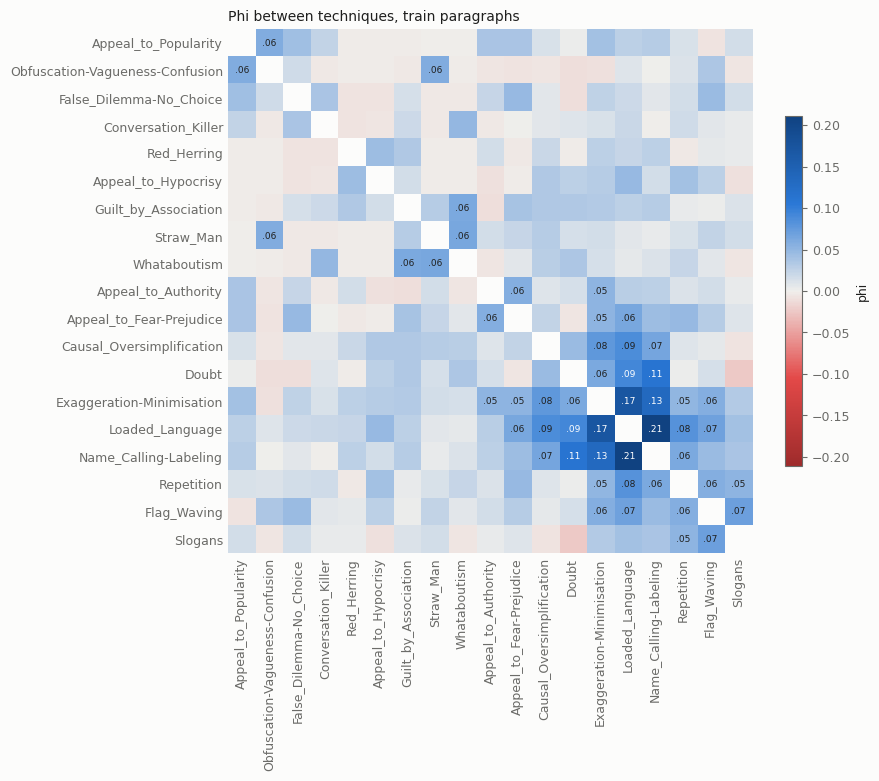

In [5]:
phi = train[techniques].corr()
order = [techniques[i] for i in leaves_list(linkage(squareform(1 - phi.to_numpy(), checks=False), method="average"))]

limit = np.abs(upper(phi)).max()
fig, ax = plt.subplots(figsize=(9, 8))
image = heatmap(ax, phi.loc[order, order], DIVERGING, -limit, limit, 0.05, "Phi between techniques, train paragraphs")
fig.colorbar(image, ax=ax, shrink=0.6, label="phi")
plt.tight_layout()
plt.show()

### Pairs, with counts and significance

Phi is easy to compare across pairs but hides the counts behind it. The table adds:
- `both`: paragraphs with both techniques; `expected`: how many there would be if the two were independent
- `lift`: both / expected (1 = independent)
- `P(B|A)` and `P(A|B)`: how often one technique appears given the other. These differ when base rates differ.
- `q`: Fisher's exact test p-value, Benjamini-Hochberg corrected across all 171 pairs

In [6]:
def pair_table(df):
    X = df[techniques].to_numpy(bool)
    n = len(X)
    corr = df[techniques].corr()
    rows = []
    for a, b in combinations(techniques, 2):
        xa, xb = X[:, techniques.index(a)], X[:, techniques.index(b)]
        na, nb, both = xa.sum(), xb.sum(), (xa & xb).sum()
        odds_ratio, p = fisher_exact([[both, na - both], [nb - both, n - na - nb + both]])
        rows.append(
            {
                "A": a,
                "B": b,
                "n_A": na,
                "n_B": nb,
                "both": both,
                "expected": na * nb / n,
                "lift": both / (na * nb / n),
                "P(B|A)": both / na,
                "P(A|B)": both / nb,
                "phi": corr.loc[a, b],
                "odds_ratio": odds_ratio,
                "p": p,
            }
        )
    pairs = pd.DataFrame(rows)
    pairs["q"] = false_discovery_control(pairs["p"])
    return pairs


pairs = pair_table(train)
significant = pairs[pairs["q"] < 0.05]
print(f"{len(significant)} of {len(pairs)} pairs differ from independence at q < 0.05: "
      f"{(significant['phi'] > 0).sum()} positive, {(significant['phi'] < 0).sum()} negative")

display_columns = ["A", "B", "n_A", "n_B", "both", "expected", "lift", "P(B|A)", "P(A|B)", "phi", "q"]
print("\nStrongest positive pairs")
pairs.sort_values("phi", ascending=False)[display_columns].head(15).round(3)

53 of 171 pairs differ from independence at q < 0.05: 53 positive, 0 negative

Strongest positive pairs


,A,B,n_A,n_B,both,expected,lift,P(B|A),P(A|B),phi,q
146,Loaded_Language,Name_Calling-Labeling,1809,979,426,186.461,2.285,0.235,0.435,0.211,0.000
144,Loaded_Language,Exaggeration-Minimisation,1809,466,227,88.755,2.558,0.125,0.487,0.172,0.000
157,Exaggeration-Minimisation,Name_Calling-Labeling,466,979,131,48.033,2.727,0.281,0.134,0.133,0.000
165,Name_Calling-Labeling,Doubt,979,518,126,53.393,2.360,0.129,0.243,0.111,0.000
147,Loaded_Language,Doubt,1809,518,176,98.659,1.784,0.097,0.340,0.091,0.000
72,Causal_Oversimplification,Loaded_Language,213,1809,88,40.568,2.169,0.413,0.049,0.086,0.000
143,Loaded_Language,Repetition,1809,544,175,103.611,1.689,0.097,0.322,0.082,0.000
74,Causal_Oversimplification,Exaggeration-Minimisation,213,466,34,10.450,3.253,0.160,0.073,0.078,0.000
56,Flag_Waving,Slogans,287,153,19,4.623,4.110,0.066,0.124,0.070,0.000
58,Flag_Waving,Loaded_Language,287,1809,98,54.662,1.793,0.341,0.054,0.068,0.000


In [7]:
print("Strongest negative pairs: techniques that appear together less than chance")
pairs.sort_values("phi")[display_columns].head(10).round(3)

Strongest negative pairs: techniques that appear together less than chance


,A,B,n_A,n_B,both,expected,lift,P(B|A),P(A|B),phi,q
132,Slogans,Doubt,153,518,2,8.344,0.240,0.013,0.004,-0.023,0.055
90,False_Dilemma-No_Choice,Doubt,122,518,4,6.654,0.601,0.033,0.008,-0.011,0.622
162,Obfuscation-Vagueness-Confusion,Doubt,18,518,0,0.982,0.000,0.000,0.000,-0.010,0.850
16,Appeal_to_Authority,Guilt_by_Association,154,59,0,0.957,0.000,0.000,0.000,-0.010,1.000
156,Exaggeration-Minimisation,Obfuscation-Vagueness-Confusion,466,18,0,0.883,0.000,0.000,0.000,-0.010,1.000
17,Appeal_to_Authority,Appeal_to_Hypocrisy,154,40,0,0.649,0.000,0.000,0.000,-0.008,1.000
134,Slogans,Appeal_to_Hypocrisy,153,40,0,0.644,0.000,0.000,0.000,-0.008,1.000
70,Causal_Oversimplification,Slogans,213,153,2,3.431,0.583,0.009,0.013,-0.008,0.811
46,Appeal_to_Fear-Prejudice,Obfuscation-Vagueness-Confusion,310,18,0,0.587,0.000,0.000,0.000,-0.008,1.000
81,False_Dilemma-No_Choice,Red_Herring,122,44,0,0.565,0.000,0.000,0.000,-0.008,1.000


## Conditional co-occurrence: P(column | row)

Phi is symmetric, but co-occurrence is not. Each cell is the share of paragraphs carrying the row technique that also carry the column technique. A common technique like `Loaded_Language` appears in many rows' paragraphs without them appearing in its paragraphs. Values ≥ 0.2 are printed.

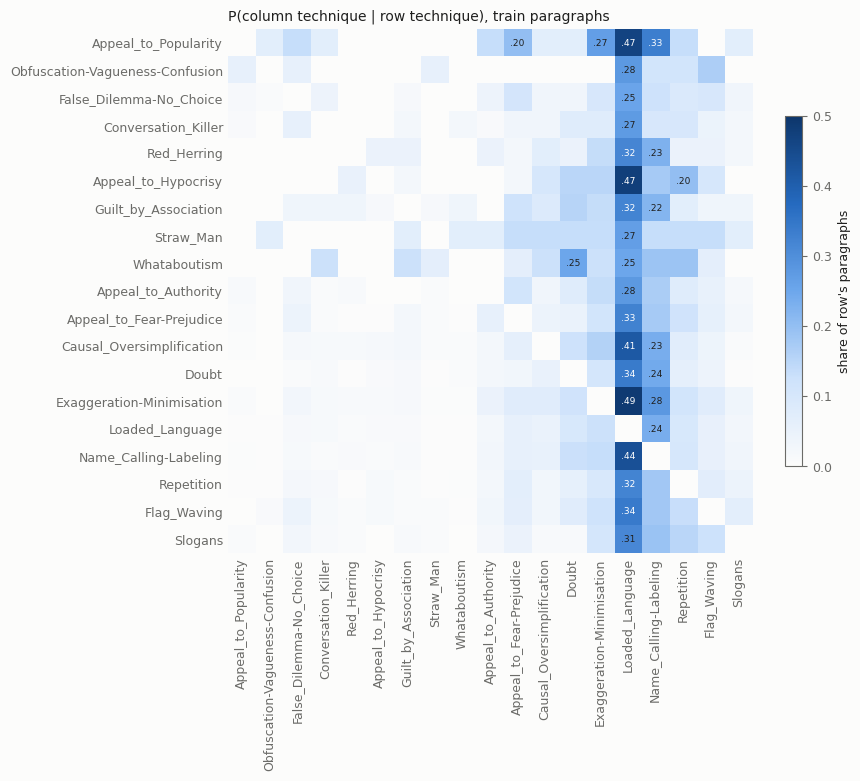

In [8]:
X = train[techniques].to_numpy(float)
conditional = pd.DataFrame((X.T @ X) / X.sum(axis=0)[:, None], index=techniques, columns=techniques)

fig, ax = plt.subplots(figsize=(9, 8))
# Scale to the largest value, rounded up, so the colours use the whole ramp
# The matrix is asymmetric, so take the maximum over every off-diagonal cell
off_diagonal = conditional.to_numpy()[~np.eye(len(techniques), dtype=bool)]
top = np.ceil(off_diagonal.max() * 10) / 10
image = heatmap(ax, conditional.loc[order, order], SEQUENTIAL, 0, top, 0.2, "P(column technique | row technique), train paragraphs")
fig.colorbar(image, ax=ax, shrink=0.6, label="share of row's paragraphs")
plt.tight_layout()
plt.show()

## Is it just paragraph length?

Longer paragraphs have room for more techniques, so length alone produces positive co-occurrence. The partial correlation removes the part of each label that a linear function of log word count predicts, then correlates what is left. Word counts are the only use of the text here.

In [9]:
def partial_phi(df):
    """Correlation of technique labels after regressing each on log(1 + words)."""
    log_words = np.log1p(df["text"].str.split().str.len().to_numpy())
    Z = np.column_stack([np.ones(len(df)), log_words])
    Y = df[techniques].to_numpy(float)
    residuals = Y - Z @ np.linalg.lstsq(Z, Y, rcond=None)[0]
    return pd.DataFrame(np.corrcoef(residuals.T), index=techniques, columns=techniques), log_words


partial, log_words = partial_phi(train)
with_length = pd.Series({t: pearsonr(train[t], log_words).statistic for t in techniques}, name="r with log words")
print(f"Correlation of the number of techniques with log words: {pearsonr(train[techniques].sum(axis=1), log_words).statistic:.2f}\n")
print(with_length.sort_values(ascending=False).round(3).to_string())

Correlation of the number of techniques with log words: 0.39

Loaded_Language                    0.285
Name_Calling-Labeling              0.197
Exaggeration-Minimisation          0.160
Repetition                         0.145
Causal_Oversimplification          0.120
Appeal_to_Fear-Prejudice           0.119
Doubt                              0.119
Flag_Waving                        0.092
Appeal_to_Authority                0.091
False_Dilemma-No_Choice            0.071
Guilt_by_Association               0.058
Appeal_to_Hypocrisy                0.055
Slogans                            0.049
Red_Herring                        0.043
Appeal_to_Popularity               0.037
Straw_Man                          0.027
Whataboutism                       0.025
Conversation_Killer                0.024
Obfuscation-Vagueness-Confusion    0.020


## Do the correlations hold up?

Each dot is one technique pair. Points on the dashed line mean the two estimates agree.

- **Train vs dev.** Dev is a different set of articles, segmented into shorter paragraphs.
- **Raw vs length-controlled.** Points below the line are pairs partly explained by paragraph length.
- **Paragraph vs article level.** At the article level, each article is a vector of the share of its paragraphs with each technique, correlated across the 446 train articles with Spearman. Techniques that sit in neighbouring paragraphs of the same article, rather than in the same paragraph, show up here but not in the paragraph-level phi.

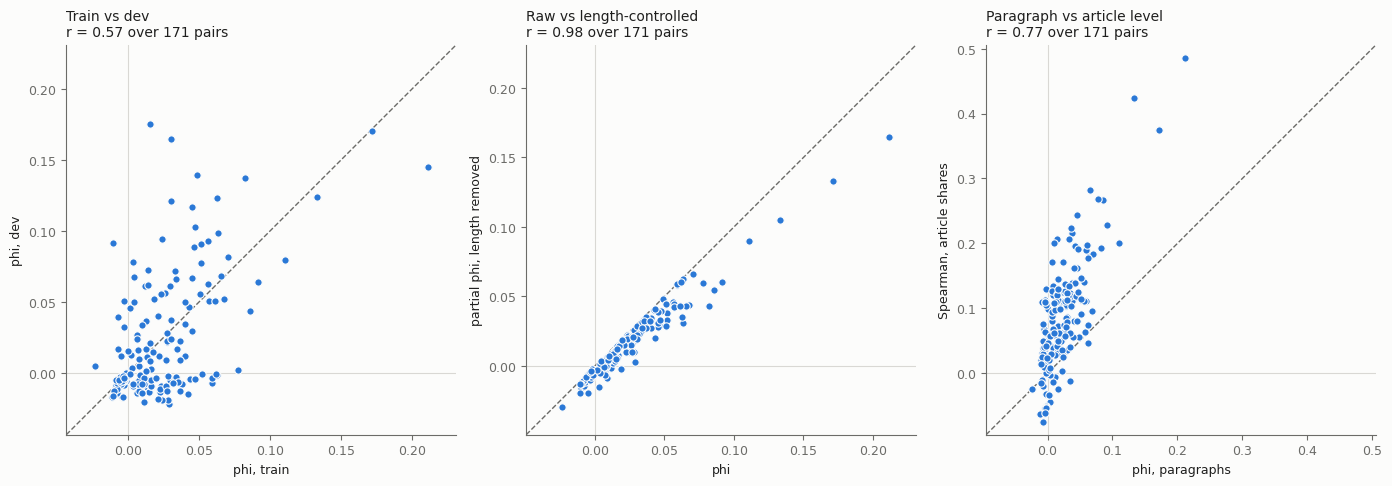

In [10]:
phi_dev = dev[techniques].corr()
article_share = train.groupby("article_id")[techniques].mean()
article_corr = article_share.corr(method="spearman")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
scatter(axes[0], upper(phi), upper(phi_dev), "phi, train", "phi, dev", "Train vs dev")
scatter(axes[1], upper(phi), upper(partial), "phi", "partial phi, length removed", "Raw vs length-controlled")
scatter(axes[2], upper(phi), upper(article_corr), "phi, paragraphs", "Spearman, article shares", "Paragraph vs article level")
plt.tight_layout()
plt.show()

In [11]:
# The pairs whose estimates move most between the views above
views = pd.DataFrame(
    {
        "A": pairs["A"],
        "B": pairs["B"],
        "both (train)": pairs["both"],
        "phi train": upper(phi),
        "phi dev": upper(phi_dev),
        "partial phi": upper(partial),
        "article-level": upper(article_corr),
    }
)
views["dev - train"] = views["phi dev"] - views["phi train"]
print("Largest train-dev differences")
display(views.reindex(views["dev - train"].abs().sort_values(ascending=False).index).head(8).round(3))
print("Pairs much stronger at article level than paragraph level")
views.assign(gap=views["article-level"] - views["phi train"]).sort_values("gap", ascending=False).head(8).round(3)

Largest train-dev differences


,A,B,both (train),phi train,phi dev,partial phi,article-level,dev - train
170,Guilt_by_Association,Appeal_to_Hypocrisy,1,0.016,0.175,0.012,0.050,0.160
103,Straw_Man,Guilt_by_Association,1,0.031,0.165,0.029,0.079,0.134
16,Appeal_to_Authority,Guilt_by_Association,0,-0.010,0.092,-0.016,0.020,0.102
117,Whataboutism,Conversation_Killer,2,0.049,0.140,0.048,0.056,0.091
166,Name_Calling-Labeling,Guilt_by_Association,13,0.030,0.121,0.019,0.112,0.091
74,Causal_Oversimplification,Exaggeration-Minimisation,34,0.078,0.002,0.059,0.268,-0.075
154,Repetition,Guilt_by_Association,4,0.004,0.078,-0.005,0.008,0.075
77,Causal_Oversimplification,Doubt,26,0.045,0.117,0.031,0.244,0.072


Pairs much stronger at article level than paragraph level


,A,B,both (train),phi train,phi dev,partial phi,article-level,dev - train,gap
157,Exaggeration-Minimisation,Name_Calling-Labeling,131,0.133,0.124,0.105,0.424,-0.009,0.291
146,Loaded_Language,Name_Calling-Labeling,426,0.211,0.145,0.165,0.486,-0.066,0.275
76,Causal_Oversimplification,Name_Calling-Labeling,50,0.066,0.069,0.043,0.282,0.003,0.216
144,Loaded_Language,Exaggeration-Minimisation,227,0.172,0.170,0.133,0.375,-0.001,0.203
77,Causal_Oversimplification,Doubt,26,0.045,0.117,0.031,0.244,0.072,0.199
83,False_Dilemma-No_Choice,Slogans,4,0.015,-0.014,0.012,0.208,-0.029,0.192
140,Conversation_Killer,Doubt,7,0.010,-0.007,0.007,0.201,-0.017,0.191
74,Causal_Oversimplification,Exaggeration-Minimisation,34,0.078,0.002,0.059,0.268,-0.075,0.191


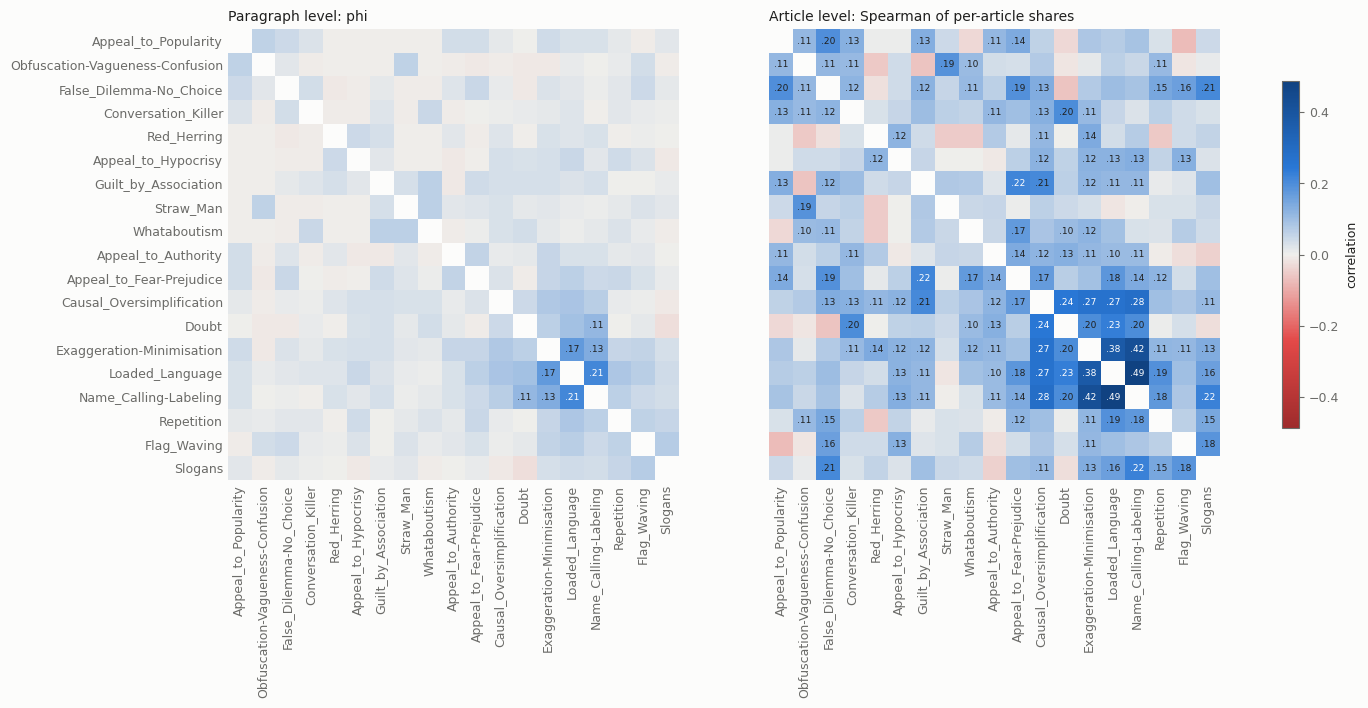

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7.5))
limit = max(np.abs(upper(phi)).max(), np.abs(upper(article_corr)).max())
heatmap(axes[0], phi.loc[order, order], DIVERGING, -limit, limit, 0.1, "Paragraph level: phi")
image = heatmap(axes[1], article_corr.loc[order, order], DIVERGING, -limit, limit, 0.1, "Article level: Spearman of per-article shares")
axes[1].set_yticklabels([])
fig.colorbar(image, ax=axes, shrink=0.6, label="correlation")
plt.show()

## Do the correlations follow the task's six categories?

The task groups the techniques into six categories. If labels in the same category correlate more than labels in different categories, the categories are a natural first guess for multitask branches. If they don't, a data-driven grouping may fit better. The clustering below uses the same 1 - phi distance as the heatmap order.

In [13]:
category = np.array([CATEGORY[t] for t in techniques])
same = upper(pd.DataFrame(category[:, None] == category[None, :]))

for name, matrix in {"paragraph phi": phi, "partial phi": partial, "article-level": article_corr}.items():
    values = upper(matrix)
    print(f"{name:>14}: mean within category {values[same].mean():.3f} ({same.sum()} pairs), "
          f"between categories {values[~same].mean():.3f} ({(~same).sum()} pairs)")

# For each category, the mean phi among its own techniques
within = {}
for c in dict.fromkeys(category):
    members = [t for t in techniques if CATEGORY[t] == c]
    within[c] = {
        "techniques": len(members),
        "mean phi within": upper(phi.loc[members, members]).mean() if len(members) > 1 else np.nan,
        "mean phi with others": phi.loc[members, [t for t in techniques if t not in members]].to_numpy().mean(),
    }
pd.DataFrame(within).T.round(3)

 paragraph phi: mean within category 0.034 (23 pairs), between categories 0.021 (148 pairs)
   partial phi: mean within category 0.025 (23 pairs), between categories 0.014 (148 pairs)
 article-level: mean within category 0.083 (23 pairs), between categories 0.087 (148 pairs)


,techniques,mean phi within,mean phi with others
Justification,4.0,0.028,0.020
Simplification,2.0,0.008,0.022
Distraction,3.0,0.019,0.013
Call,2.0,0.005,0.013
Manipulative wording,4.0,0.052,0.032
Attack on reputation,4.0,0.039,0.024


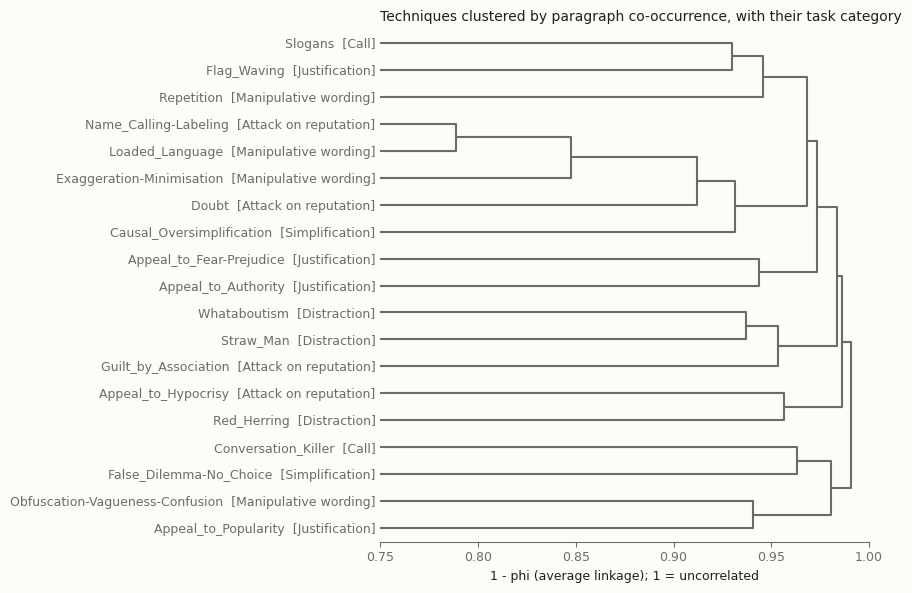

category,Attack on reputation,Call,Distraction,Justification,Manipulative wording,Simplification
cluster,,,,,,
1,0,0,0,1,1,0
2,0,1,0,0,0,1
3,1,0,1,0,0,0
4,1,0,2,0,0,0
5,0,0,0,2,0,0
6,2,1,0,1,3,1


In [14]:
tree = linkage(squareform(1 - phi.to_numpy(), checks=False), method="average")

fig, ax = plt.subplots(figsize=(9, 6))
dendrogram(
    tree,
    labels=[f"{t}  [{CATEGORY[t]}]" for t in techniques],
    orientation="right",
    color_threshold=0,
    above_threshold_color=MUTED,
    leaf_font_size=9,
    ax=ax,
)
# Every merge happens between about 0.8 and 1, so zoom in; 1 means uncorrelated
ax.set_xlim(0.75, 1.0)
ax.set_xlabel("1 - phi (average linkage); 1 = uncorrelated")
ax.set_title("Techniques clustered by paragraph co-occurrence, with their task category", loc="left", fontsize=10)
ax.spines[["left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

# Cut the tree into as many clusters as there are categories and compare
clusters = pd.Series(fcluster(tree, t=6, criterion="maxclust"), index=techniques, name="cluster")
pd.crosstab(clusters, pd.Series(category, index=techniques, name="category"))

In [15]:
# The cluster members, to read alongside the crosstab
for c, members in clusters.groupby(clusters).groups.items():
    print(f"Cluster {c}: {', '.join(members)}")

Cluster 1: Appeal_to_Popularity, Obfuscation-Vagueness-Confusion
Cluster 2: False_Dilemma-No_Choice, Conversation_Killer
Cluster 3: Red_Herring, Appeal_to_Hypocrisy
Cluster 4: Straw_Man, Whataboutism, Guilt_by_Association
Cluster 5: Appeal_to_Authority, Appeal_to_Fear-Prejudice
Cluster 6: Flag_Waving, Causal_Oversimplification, Slogans, Loaded_Language, Repetition, Exaggeration-Minimisation, Name_Calling-Labeling, Doubt


## What this suggests for a multitask design

These are hypotheses for the multitask stage, not results.

- **`compare_task_structures.py` tests these ideas.** With paragraph-level correlations this weak, a multilabel head has little label dependence to exploit. If it beats 19 separate models, the gain more likely comes from sharing one encoder across techniques, which matters most for the 7 techniques with under 60 train paragraphs.
- **Branch candidates.** A data-driven structure gives the core group (`Loaded_Language`, `Name_Calling-Labeling`, `Exaggeration-Minimisation`, `Doubt`) its own trunk and leaves the rest separate: `core_trunk` in the script. `Repetition` and `Causal_Oversimplification` are borderline members. The six task categories are the theory-driven alternative (`category_heads`). The data give them little support, so they are run as a comparison rather than assumed.
- **Don't group rare techniques by their correlations.** Their pairwise estimates rest on 0 to 2 shared paragraphs and don't replicate in dev.
- **Article context may matter more than label coupling.** Co-occurrence is much stronger across an article than within a paragraph. That suggests features from neighbouring paragraphs, or an article-level auxiliary task (subtask 1 genre, subtask 2 frames), as multitask candidates.